In [ ]:
!apt-get install unrar
!pip install mtcnn


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:6.1.5-1ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 67.0 MB/s eta 0:00:00


In [ ]:
!unrar x "/content/dataset.rar" "/content/dataset/"
!unrar x "/content/toys.rar" "/content/dataset/"



UNRAR 6.11 beta 1 freeware      Copyright (c) 1993-2022 Alexander Roshal


Extracting from /content/dataset.rar

Creating    /content/dataset                                          OK
Creating    /content/dataset/dataset                                  OK
Creating    /content/dataset/dataset/Calm_image                       OK
Extracting  /content/dataset/dataset/Calm_image/7-months-baby-laying-floor.jpg       0%  OK 
Extracting  /content/dataset/dataset/Calm_image/7-months-baby-laying-flooree.png       0%  OK 
Extracting  /content/dataset/dataset/Calm_image/adorable-baby-crawling-playing-floor-with-toy.jpg       1%  OK 
Extracting  /content/dataset/dataset/Calm_image/adorable-baby-enjoying-tummy-time-indoors.jpg       1%  OK 
Extracting  /content/dataset/dataset/Calm_image/adorable-baby-playing-with-toy-home-floor.jpg       2%  OK 
Extracting  /content/dataset/dataset/Calm_image/adorable-baby-sitting-beautiful-swing-decorated-christmas.

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping

import numpy as np
import cv2
import os
import random
from matplotlib import pyplot as plt
from mtcnn import MTCNN


In [ ]:
def crop_face(path, size=128):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    faces = detector.detect_faces(img)
    if faces:
        x, y, w, h = faces[0]['box']
        face = img[y:y+h, x:x+w]
        face = cv2.resize(face, (size, size))
        return face

    return cv2.resize(img, (size, size))



In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import random

class FaceDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, file_paths, labels, batch_size=32, augment=True):
        self.file_paths = file_paths
        self.labels = labels
        self.batch_size = batch_size
        self.augment = augment
        self.indices = np.arange(len(file_paths))

    def __len__(self):
        return int(np.ceil(len(self.file_paths) / self.batch_size))

    def on_epoch_end(self):
        np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        ids = self.indices[idx*self.batch_size:(idx+1)*self.batch_size]

        imgs = []
        labs = []
        for i in ids:
            img = crop_face(self.file_paths[i])  # get face crop
            if self.augment:
                img = self.apply_augmentation(img)
            img = img / 255.0  # normalize
            imgs.append(img)
            labs.append(self.labels[i])

        return np.array(imgs, dtype=np.float32), np.array(labs)

    def apply_augmentation(self, img):
        # Horizontal flip
        if random.random() < 0.5:
            img = cv2.flip(img, 1)

        # Random rotation (-15 to +15 degrees)
        angle = random.uniform(-15, 15)
        h, w = img.shape[:2]
        M = cv2.getRotationMatrix2D((w//2, h//2), angle, 1)
        img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)

        # Random brightness adjustment
        if random.random() < 0.5:
            factor = 0.7 + random.random() * 0.6  # 0.7 to 1.3
            img = np.clip(img * factor, 0, 255).astype(np.uint8)

        return img


In [ ]:
happy_dir = "/content/dataset/dataset/Happy_image"
sad_dir   = "/content/dataset/dataset/Sad_image"
calm_dir = "/content/dataset/dataset/Calm_image"
excited_dir = "/content/dataset/dataset/Excited_image"

happy_paths = [os.path.join(happy_dir, f) for f in os.listdir(happy_dir)]
sad_paths   = [os.path.join(sad_dir, f) for f in os.listdir(sad_dir)]
calm_paths = [os.path.join(calm_dir, f) for f in os.listdir(calm_dir)]
excited_paths = [os.path.join(excited_dir, f) for f in os.listdir(excited_dir)]

all_paths = happy_paths + sad_paths + calm_paths + excited_paths

labels = (
    [0]*len(happy_paths) +
    [1]*len(sad_paths) +
    [2]*len(calm_paths) +
    [3]*len(excited_paths)
)

# shuffle dataset
combined = list(zip(all_paths, labels))
random.shuffle(combined)
all_paths, labels = zip(*combined)

split = int(0.8 * len(all_paths))
train_paths, val_paths = all_paths[:split], all_paths[split:]
train_labels, val_labels = labels[:split], labels[split:]

train_data = FaceDataGenerator(train_paths, train_labels, batch_size=32)
val_data   = FaceDataGenerator(val_paths, val_labels, batch_size=32)

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model

# EfficientNetB0 with 128x128 input
base = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(128,128,3))

for layer in base.layers[-30:]:
    layer.trainable = True

x = GlobalAveragePooling2D()(base.output)
x = Dense(64, activation='relu')(x)
output = Dense(4, activation='softmax')(x)  # 4 classes

model = Model(base.input, output)
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()



16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 128, 128,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 128, 128,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 129, 129,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 64, 64,    │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 64, 64,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 64, 64,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 64, 64,    │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 64, 64,    │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 64, 64,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 64, 64,    │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 64, 64,    │        512 │ block1a_se_excit

 Total params: 4,131,815 (15.76 MB)

 Trainable params: 4,089,792 (15.60 MB)

 Non-trainable params: 42,023 (164.16 KB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
from mtcnn import MTCNN

detector = MTCNN()

es = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,  # start with 10, EarlyStopping will cut it short if needed
    callbacks=[es]
)

model.save("baby_emotion_model.h5")

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1151s 109s/step - accuracy: 0.4070 - loss: 1.3297 - val_accuracy: 0.3250 - val_loss: 1.4284
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 960s 97s/step - accuracy: 0.7161 - loss: 0.7732 - val_accuracy: 0.3250 - val_loss: 1.4949
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 992s 108s/step - accuracy: 0.8215 - loss: 0.5301 - val_accuracy: 0.3250 - val_loss: 1.4868
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 937s 101s/step - accuracy: 0.8900 - loss: 0.3158 - val_accuracy: 0.3250 - val_loss: 1.3962
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 955s 96s/step - accuracy: 0.9340 - loss: 0.2179 - val_accuracy: 0.1625 - val_loss: 1.4818
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 992s 99s/step - accuracy: 0.9357 - loss: 0.2021 - val_accuracy: 0.1625 - val_loss: 1.4733
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 978s 104s/step - accuracy: 0.9607 - loss: 0.1117 - val_accuracy: 0.3250 - val_loss: 1.8723


In [ ]:
def predict_emotion(img_path):
    # Crop face and normalize
    img = crop_face(img_path, size=128)
    img = img / 255.0
    img = np.expand_dims(img, 0)  # add batch dimension

    # Predict probabilities for 4 classes
    pred = model.predict(img)[0]  # shape: (4,)

    # Get the index with highest probability
    class_idx = np.argmax(pred)

    # Map index to emotion
    emotions = {0: "Happy", 1: "Sad", 2: "Calm", 3: "Excited"}
    return emotions[class_idx]



Predicted emotion: Calm
Recommended toys: ['/content/dataset/Toys/Calm/download.jpeg', '/content/dataset/Toys/Calm/images (3).jpeg', '/content/dataset/Toys/Calm/download (7).jpeg']
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


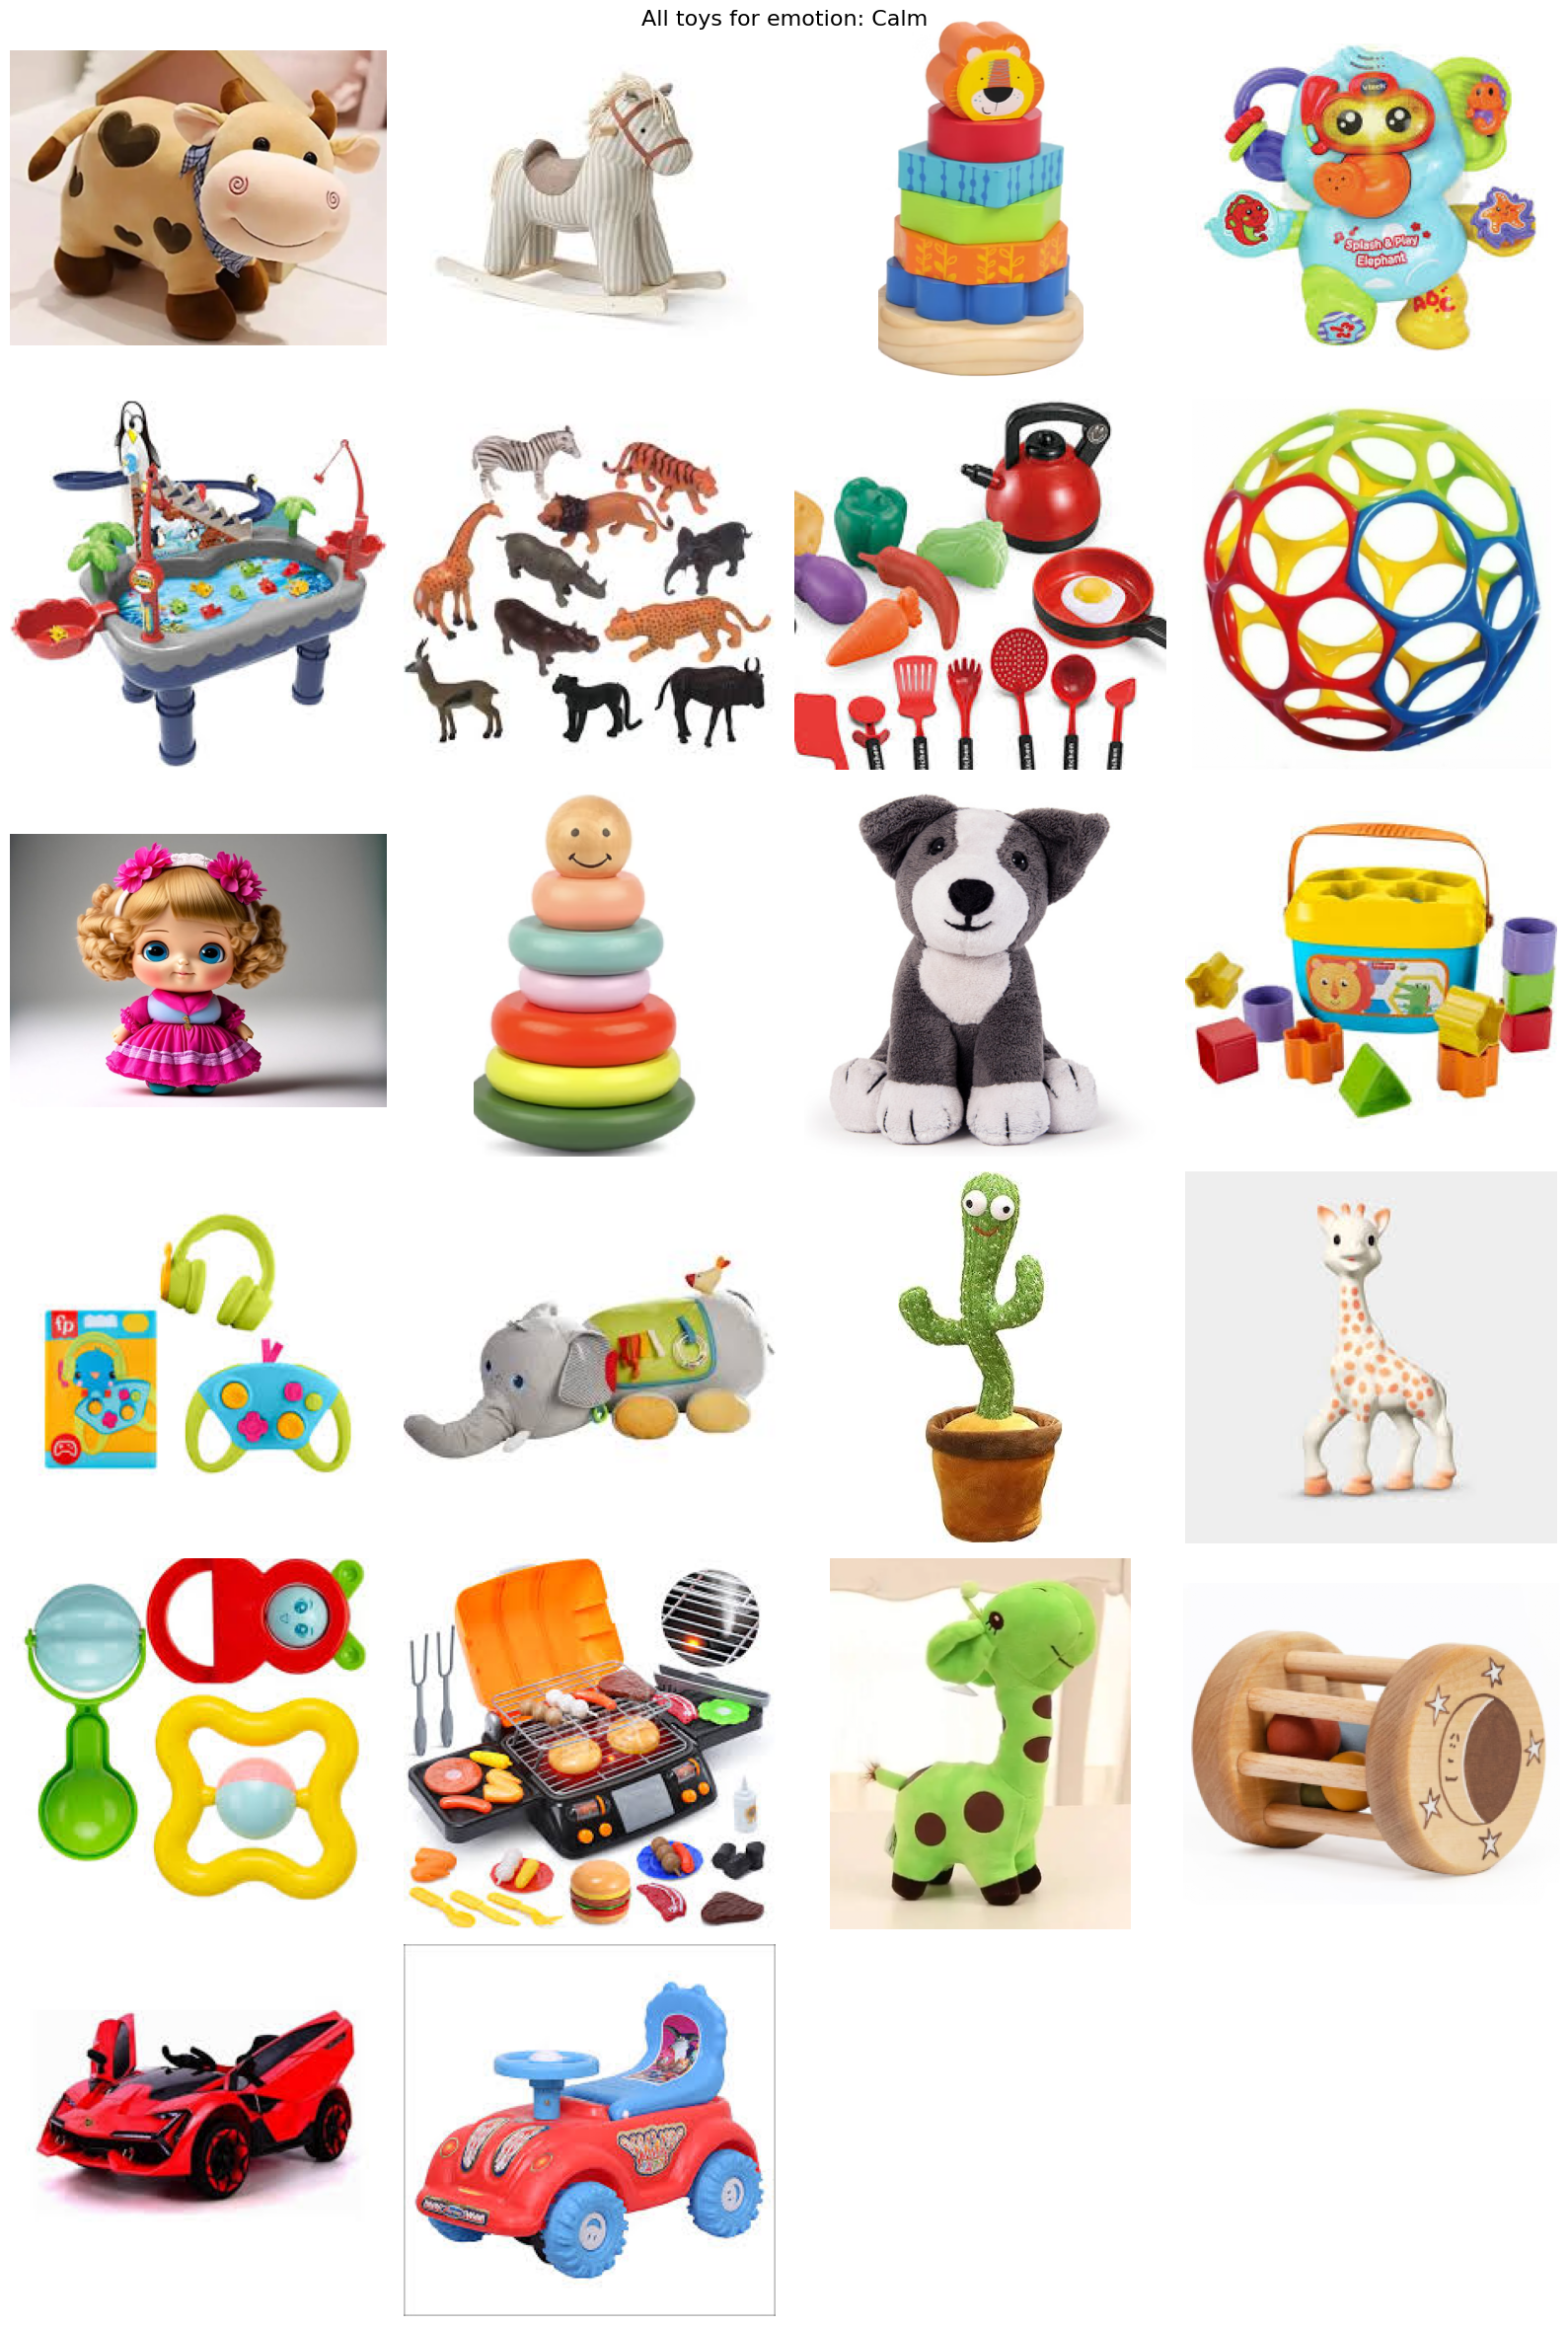

In [ ]:
def recommend_toys(emotion, num=3):
    folder = f"/content/dataset/Toys/{emotion}/"

    if not os.path.exists(folder):
        raise ValueError(f"No toy folder found for emotion: {emotion}")

    images = os.listdir(folder)

    if len(images) < num:
        raise ValueError(
            f"Not enough toy images for {emotion}. "
            f"Requested {num}, found {len(images)}"
        )

    chosen = random.sample(images, num)
    return [os.path.join(folder, img) for img in chosen]

def get_all_toys(emotion):
    folder = f"/content/dataset/Toys/{emotion}/"
    if not os.path.exists(folder):
        raise ValueError(f"No toy folder found for emotion: {emotion}")
    images = os.listdir(folder)
    return [os.path.join(folder, img) for img in images]

# --------------------------------------------------
# 3. Full usage
# --------------------------------------------------

img_path = "/content/istockphoto-156201476-170667a.jpg"


print("Predicted emotion:", emotion)
print("Recommended toys:", toy_images)
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import math

def show_all_toys(toy_images, emotion):
    n = len(toy_images)
    cols = 4                      # number of columns
    rows = math.ceil(n / cols)    # auto rows

    plt.figure(figsize=(4 * cols, 4 * rows))
    plt.suptitle(f"All toys for emotion: {emotion}", fontsize=16)

    for i, img_path in enumerate(toy_images):
        img = mpimg.imread(img_path)
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.axis("off")

    plt.tight_layout()
    plt.show()


emotion = predict_emotion(img_path)

all_toy_images = get_all_toys(emotion)
show_all_toys(all_toy_images, emotion)


In [ ]:
from sklearn.metrics import classification_report